# Task 1 — Anti-Cheat model experiments

This notebook follows the order of the experiments: load the two EDA datasets, establish baselines, tune the promising models, compare feature sets, then try three more model libraries. Run it from top to bottom. Each experiment loads its saved result when present and trains only when its artifact is missing.

Metric: **macro F₂**. Fitting, hyperparameter search, and threshold selection use the development split. The same 20% holdout is used for reporting and comparison; Test is used only for schema and final inference checks.

## 1. Load saved datasets

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (fbeta_score, make_scorer, classification_report,
                             ConfusionMatrixDisplay, precision_recall_curve,
                             average_precision_score, roc_auc_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, TunedThresholdClassifierCV

from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

SEED = set_seed()
TARGET, ID = "is_cheater", "player_id"
SCORE = make_scorer(fbeta_score, beta=2, average="macro", zero_division=0)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid")

def load_dataset(name):
    card_path = SRC / "task1" / "data" / "eda" / f"{name}.json"
    card = json.loads(card_path.read_text(encoding="utf-8"))
    def read_split(split):
        path = SRC / card["splits"][split]["path"]
        return pd.read_parquet(path) if card["format"] == "parquet" else pd.read_csv(path)
    return card, read_split("train"), read_split("test")

datasets = {
    "original": load_dataset("eda_original_v1"),
    "combined": load_dataset("eda_combined_v1"),
}
original_train, original_test = datasets["original"][1:]
combined_train, combined_test = datasets["combined"][1:]
assert original_train[ID].equals(combined_train[ID])
assert original_train[TARGET].equals(combined_train[TARGET])
assert original_test[ID].equals(combined_test[ID])
assert original_train[TARGET].notna().all()
assert set(original_train[TARGET].unique()) == {0, 1}
for _, train, test in datasets.values():
    assert train.drop(columns=[TARGET]).columns.tolist() == test.columns.tolist()
    assert train[ID].is_unique and test[ID].is_unique

display(pd.DataFrame([
    {"dataset": card["name"], "train_rows": len(train), "test_rows": len(test),
     "features": test.shape[1] - 1}
    for card, train, test in datasets.values()
]))

,dataset,train_rows,test_rows,features
0,eda_original_v1,90816,25889,31
1,eda_combined_v1,90816,25889,45


In [2]:
y = original_train[TARGET].astype(int)
dev_idx, valid_idx = train_test_split(
    np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED
)
y_dev, y_valid = y.iloc[dev_idx], y.iloc[valid_idx]
X_dev, X_valid = {}, {}
for label, (_, train, test) in datasets.items():
    features = test.columns.drop(ID).tolist()
    X_dev[label] = train.iloc[dev_idx][features]
    X_valid[label] = train.iloc[valid_idx][features]
assert y_dev.index.intersection(y_valid.index).empty
assert X_dev["original"].index.equals(X_dev["combined"].index)
assert X_valid["original"].index.equals(X_valid["combined"].index)
display(pd.DataFrame({
    "development": y_dev.value_counts().sort_index(),
    "validation": y_valid.value_counts().sort_index(),
    "development_pct": y_dev.value_counts(normalize=True).sort_index().mul(100).round(2),
    "validation_pct": y_valid.value_counts(normalize=True).sort_index().mul(100).round(2),
}))

,development,validation,development_pct,validation_pct
is_cheater,,,,
0,47272,11819,65.07,65.07
1,25380,6345,34.93,34.93


### Reuse an experiment when its artifact already exists

In [3]:
SAVE_DIR = SRC / "task1" / "save"

def model_paths(name):
    return (SAVE_DIR / f"{name}.joblib", SAVE_DIR / f"{name}.json",
            SAVE_DIR / f"{name}-evaluation.json")

def saved_result(name, dataset):
    model_path, card_path, eval_path = model_paths(name)
    present = [p.exists() for p in (model_path, card_path, eval_path)]
    if not any(present):
        return None
    if not model_path.exists() or not card_path.exists():
        raise RuntimeError(f"Incomplete artifact for {name}; inspect files before retrying")
    card = json.loads(card_path.read_text(encoding="utf-8"))
    expected = datasets[dataset][0]["name"]
    if card["data_name"] != expected:
        raise ValueError(f"{name} is linked to a different dataset")
    if not eval_path.exists():
        model = load_model(name)
        pred = np.asarray(model.predict(X_valid[dataset])).reshape(-1)
        tuning = card["card"].get("tuning", "none")
        result = evaluate_model(
            task=1, name=name, y_true=y_valid, y_pred=pred,
            card={"split": "held-out validation 20%", "seed": SEED,
                  "tuning": tuning},
        )
        print(f"Loaded {name}; recorded missing evaluation: macro F2 = {result['score']:.5f}")
        return result
    result = json.loads(eval_path.read_text(encoding="utf-8"))
    if result["data_name"] != expected:
        raise ValueError(f"{name} evaluation is linked to a different dataset")
    if result["metric"] != "macro_F2":
        raise ValueError(f"Unexpected evaluation metric for {name}")
    print(f"Loaded {name}: macro F2 = {result['score']:.5f}")
    return result

def load_model(name):
    model_path, card_path, _ = model_paths(name)
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["model_path"] == f"task1/save/{name}.joblib"
    return joblib.load(model_path)

def record_model(name, dataset, model, idea, tuning="none"):
    save_model(task=1, name=name, model=model,
               data_name=datasets[dataset][0]["name"],
               card={"idea": idea, "seed": SEED,
                     "split": "stratified 80/20", "tuning": tuning})
    pred = np.asarray(model.predict(X_valid[dataset])).reshape(-1)
    result = evaluate_model(
        task=1, name=name, y_true=y_valid, y_pred=pred,
        card={"split": "held-out validation 20%", "seed": SEED,
              "tuning": tuning},
    )
    print(f"Trained {name}: macro F2 = {result['score']:.5f}")
    return result

## 2. Round 1 — scikit-learn

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def logistic():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(),
                         LogisticRegression(C=1.0, class_weight="balanced",
                                            max_iter=1000, random_state=SEED))

def forest():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         RandomForestClassifier(n_estimators=120, max_depth=18,
                                                min_samples_leaf=5,
                                                class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED))

def boosting():
    return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08,
                                          max_leaf_nodes=31, min_samples_leaf=30,
                                          early_stopping=False, random_state=SEED)

### Start with a majority baseline and two linear models

In [5]:
name = "t1_dummy_original_v1"
if saved_result(name, "original") is None:
    model = DummyClassifier(strategy="most_frequent")
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "Majority-class reference")

Loaded t1_dummy_original_v1: macro F2 = 0.45152


In [6]:
name = "t1_logreg_original_v1"
if saved_result(name, "original") is None:
    model = logistic()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "Logistic regression on original features")

Loaded t1_logreg_original_v1: macro F2 = 0.67733


In [7]:
name = "t1_logreg_combined_v1"
if saved_result(name, "combined") is None:
    model = logistic()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "Logistic regression on combined features")

Loaded t1_logreg_combined_v1: macro F2 = 0.67659


### Try tree models with the same split

In [8]:
name = "t1_rf_original_v1"
if saved_result(name, "original") is None:
    model = forest()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "Random forest on original features")

Loaded t1_rf_original_v1: macro F2 = 0.74157


In [9]:
name = "t1_rf_combined_v1"
if saved_result(name, "combined") is None:
    model = forest()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "Random forest on combined features")

Loaded t1_rf_combined_v1: macro F2 = 0.74117


In [10]:
name = "t1_hgb_original_v1"
if saved_result(name, "original") is None:
    model = boosting()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "HGB on original features")

Loaded t1_hgb_original_v1: macro F2 = 0.75285


In [11]:
name = "t1_hgb_combined_v1"
if saved_result(name, "combined") is None:
    model = boosting()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "HGB on combined features")

Loaded t1_hgb_combined_v1: macro F2 = 0.75250


### Search the HGB and random forest settings

In [12]:
hgb_params = {
    "max_iter": [100, 160, 220], "learning_rate": [0.04, 0.07, 0.12],
    "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 40, 80],
    "l2_regularization": [0.0, 0.5, 2.0],
}
rf_params = {
    "randomforestclassifier__n_estimators": [120, 180],
    "randomforestclassifier__max_depth": [12, 20, None],
    "randomforestclassifier__min_samples_leaf": [2, 5, 10],
    "randomforestclassifier__max_features": ["sqrt", 0.8],
}

In [13]:
name = "t1_hgb_combined_tuned_v1"
if saved_result(name, "combined") is None:
    search = RandomizedSearchCV(
        estimator=boosting(), param_distributions=hgb_params,
        n_iter=6, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev["combined"], y_dev)
    print("Best development CV macro F2:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    record_model(name, "combined", search.best_estimator_, "Development CV HGB search",
                 tuning={"cv": "3-fold stratified", "searches": 6,
                         "best_params": search.best_params_,
                         "best_cv_macro_F2": search.best_score_})

Loaded t1_hgb_combined_tuned_v1: macro F2 = 0.75289


In [14]:
name = "t1_rf_combined_tuned_v1"
if saved_result(name, "combined") is None:
    search = RandomizedSearchCV(
        estimator=forest(), param_distributions=rf_params,
        n_iter=4, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev["combined"], y_dev)
    print("Best development CV macro F2:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    record_model(name, "combined", search.best_estimator_, "Development CV random forest search",
                 tuning={"cv": "3-fold stratified", "searches": 4,
                         "best_params": search.best_params_,
                         "best_cv_macro_F2": search.best_score_})

Loaded t1_rf_combined_tuned_v1: macro F2 = 0.76680


### Tune the HGB decision threshold

In [15]:
name = "t1_hgb_combined_threshold_v1"
if saved_result(name, "combined") is None:
    base_model = clone(load_model("t1_hgb_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["combined"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "combined", threshold_model,
                 "Development CV threshold on combined features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_hgb_combined_tuned_v1"})

Loaded t1_hgb_combined_threshold_v1: macro F2 = 0.77684


### Compare those tuned settings on original features

In [16]:
name = "t1_hgb_original_matched_v1"
if saved_result(name, "original") is None:
    model = clone(load_model("t1_hgb_combined_tuned_v1"))
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "HGB with matched tuned settings on original features",
                 tuning={"parameter_source": "t1_hgb_combined_tuned_v1",
                         "cv": "source model's development CV"})

Loaded t1_hgb_original_matched_v1: macro F2 = 0.75425


In [17]:
name = "t1_rf_original_matched_v1"
if saved_result(name, "original") is None:
    model = clone(load_model("t1_rf_combined_tuned_v1"))
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "RF with matched tuned settings on original features",
                 tuning={"parameter_source": "t1_rf_combined_tuned_v1",
                         "cv": "source model's development CV"})

Loaded t1_rf_original_matched_v1: macro F2 = 0.77083


In [18]:
name = "t1_hgb_original_threshold_v1"
if saved_result(name, "original") is None:
    base_model = clone(load_model("t1_hgb_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["original"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "original", threshold_model,
                 "Development CV threshold on original features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_hgb_combined_tuned_v1"})

Loaded t1_hgb_original_threshold_v1: macro F2 = 0.77317


### Compare the models tried so far

In [19]:
def show_rankings(names, title):
    index = read_evaluation_index(1)["evaluations"]
    missing = [name for name in names if name not in index]
    if missing:
        raise ValueError(f"Missing evaluations: {missing}")
    rows = []
    for name in names:
        card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
        rows.append({"name": name, "dataset": card["data_name"],
                     "macro_F2": index[name]["score"]})
    ranking = pd.DataFrame(rows).sort_values("macro_F2", ascending=False).reset_index(drop=True)
    display(ranking.round(4))
    print("Best in this round:", ranking.iloc[0]["name"],
          f"({ranking.iloc[0]['macro_F2']:.5f})")
    fig, ax = plt.subplots(figsize=(10, max(5, len(ranking) * 0.32)))
    sns.barplot(data=ranking, x="macro_F2", y="name", hue="dataset", dodge=False, ax=ax)
    ax.set(xlim=(0, 1), title=title, xlabel="Held-out validation macro F2", ylabel="Model")
    plt.tight_layout()
    plt.show()
    return ranking

,name,dataset,macro_F2
0,t1_hgb_combined_threshold_v1,eda_combined_v1,0.7768
1,t1_hgb_original_threshold_v1,eda_original_v1,0.7732
2,t1_rf_original_matched_v1,eda_original_v1,0.7708
3,t1_rf_combined_tuned_v1,eda_combined_v1,0.7668
4,t1_hgb_original_matched_v1,eda_original_v1,0.7542
5,t1_hgb_combined_tuned_v1,eda_combined_v1,0.7529
6,t1_hgb_original_v1,eda_original_v1,0.7528
7,t1_hgb_combined_v1,eda_combined_v1,0.7525
8,t1_rf_original_v1,eda_original_v1,0.7416
9,t1_rf_combined_v1,eda_combined_v1,0.7412


Best in this round: t1_hgb_combined_threshold_v1 (0.77684)


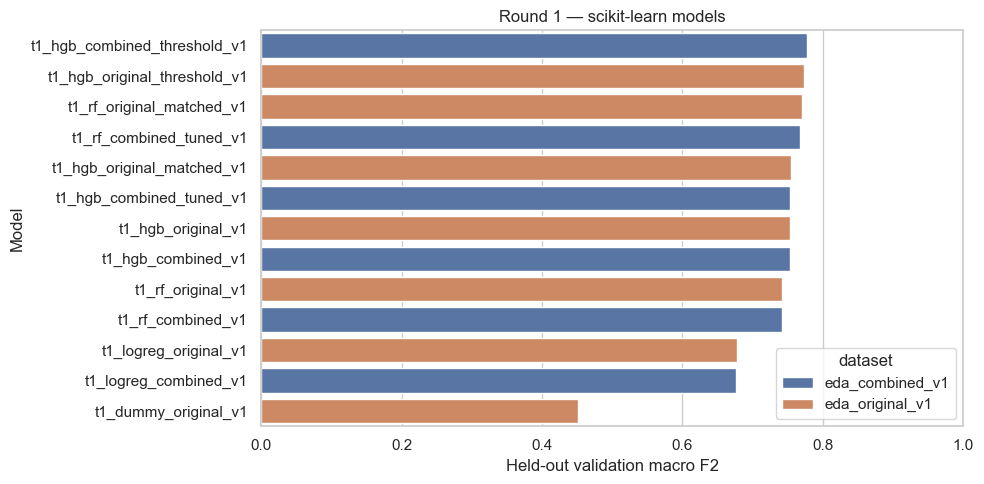

In [20]:
round1_names = [
    "t1_dummy_original_v1",
    "t1_logreg_original_v1", "t1_logreg_combined_v1",
    "t1_rf_original_v1", "t1_rf_combined_v1",
    "t1_hgb_original_v1", "t1_hgb_combined_v1",
    "t1_hgb_combined_tuned_v1", "t1_rf_combined_tuned_v1",
    "t1_hgb_combined_threshold_v1",
    "t1_hgb_original_matched_v1", "t1_rf_original_matched_v1",
    "t1_hgb_original_threshold_v1",
]
round1_ranking = show_rankings(round1_names, "Round 1 — scikit-learn models")
round1_winner = round1_ranking.iloc[0]["name"]

### Inspect the round 1 winner

In [21]:
def show_diagnostics(name):
    card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
    dataset = "original" if card["data_name"] == "eda_original_v1" else "combined"
    model = load_model(name)
    pred = np.asarray(model.predict(X_valid[dataset])).reshape(-1)
    score = fbeta_score(y_valid, pred, beta=2, average="macro", zero_division=0)
    saved = json.loads(model_paths(name)[2].read_text(encoding="utf-8"))
    assert abs(score - saved["score"]) < 1e-12
    print("Model:", name)
    print("Validation macro F2:", round(score, 5))
    print("F2 legitimate:", round(fbeta_score(y_valid, pred, beta=2, pos_label=0), 5))
    print("F2 cheater:", round(fbeta_score(y_valid, pred, beta=2, pos_label=1), 5))
    print("Threshold:", getattr(model, "best_threshold_", "default"))
    print(classification_report(y_valid, pred,
                                target_names=["Legitimate", "Cheater"], digits=4))
    ConfusionMatrixDisplay.from_predictions(y_valid, pred,
                                            display_labels=["Legitimate", "Cheater"], cmap="Blues")
    plt.title("Validation confusion matrix: " + name)
    plt.show()
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_valid[dataset])[:, 1]
        print("ROC AUC:", round(roc_auc_score(y_valid, prob), 4))
        print("Average precision (cheater):", round(average_precision_score(y_valid, prob), 4))
        precision, recall, _ = precision_recall_curve(y_valid, prob)
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(recall, precision)
        ax.set(xlabel="Cheater recall", ylabel="Cheater precision",
               title="Validation precision–recall: " + name)
        plt.show()
    return model, dataset, pred

def show_feature_importance(name, n=4000):
    card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
    dataset = "original" if card["data_name"] == "eda_original_v1" else "combined"
    model_path = model_paths(name)[0]
    data_path = SRC / datasets[dataset][0]["splits"]["train"]["path"]
    cache_path = SRC / "task1" / "models" / ".cache" / f"{name}-permutation-n{n}-r3.json"
    cache_key = {"model_mtime_ns": model_path.stat().st_mtime_ns,
                 "data_mtime_ns": data_path.stat().st_mtime_ns,
                 "seed": SEED, "sample_rows": min(n, len(valid_idx)), "repeats": 3}
    cached = json.loads(cache_path.read_text(encoding="utf-8")) if cache_path.exists() else None
    if cached is not None and cached.get("key") == cache_key:
        ranking = pd.DataFrame(cached["ranking"])
        print("Loaded permutation importance:", name)
    else:
        sample_idx = pd.Series(valid_idx).sample(n=min(n, len(valid_idx)), random_state=SEED).to_numpy()
        features = X_valid[dataset].columns
        sample_X = datasets[dataset][1].iloc[sample_idx][features]
        sample_y = y.iloc[sample_idx]
        permutation = permutation_importance(
            load_model(name), sample_X, sample_y, scoring=SCORE,
            n_repeats=3, random_state=SEED, n_jobs=1,
        )
        ranking = pd.DataFrame({"feature": features,
                                "macro_F2_drop": permutation.importances_mean,
                                "std": permutation.importances_std})
        ranking["source"] = np.where(ranking.feature.isin(original_test.columns),
                                     "original", "engineered")
        ranking = ranking.sort_values("macro_F2_drop", ascending=False).reset_index(drop=True)
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        cache_path.write_text(json.dumps({"key": cache_key,
                                          "ranking": ranking.to_dict("records")}, indent=2),
                              encoding="utf-8")
        print("Computed permutation importance:", name, "—", len(sample_X), "validation rows")
    display(ranking.round(4))
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.barplot(data=ranking.head(20), x="macro_F2_drop", y="feature",
                hue="source", dodge=False, ax=ax)
    ax.set(title="Top 20 validation permutation importances: " + name,
           xlabel="Macro F2 drop", ylabel="Feature")
    plt.tight_layout()
    plt.show()
    return ranking

Model: t1_hgb_combined_threshold_v1
Validation macro F2: 0.77684
F2 legitimate: 0.82284
F2 cheater: 0.73083
Threshold: 0.4
              precision    recall  f1-score   support

  Legitimate     0.8556    0.8150    0.8348     11819
     Cheater     0.6834    0.7437    0.7123      6345

    accuracy                         0.7901     18164
   macro avg     0.7695    0.7794    0.7736     18164
weighted avg     0.7954    0.7901    0.7920     18164



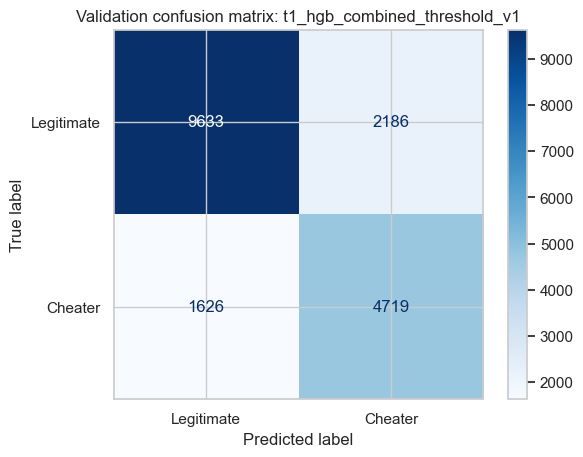

ROC AUC: 0.887
Average precision (cheater): 0.8274


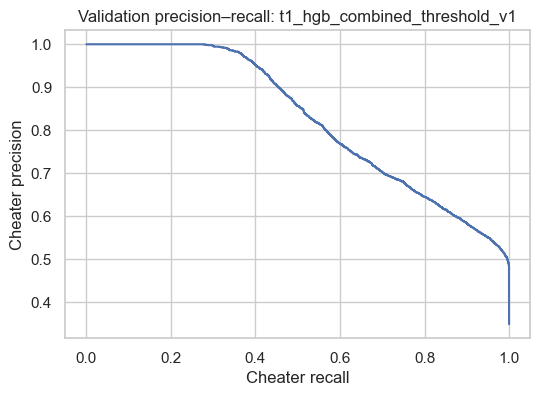

Loaded permutation importance: t1_hgb_combined_threshold_v1


,feature,macro_F2_drop,std,source
0,reports_received,0.0846,0.0017,original
1,friend_network_size,0.0789,0.0059,original
2,account_age_days,0.0716,0.0003,original
3,crosshair_placement,0.0587,0.0036,original
4,level,0.0162,0.0003,original
5,headshot_percentage,0.0110,0.0028,original
6,game_sense_score,0.0106,0.0037,original
7,kill_death_ratio,0.0090,0.0028,original
8,accuracy_score,0.0062,0.0015,original
9,spray_control_score,0.0038,0.0012,original


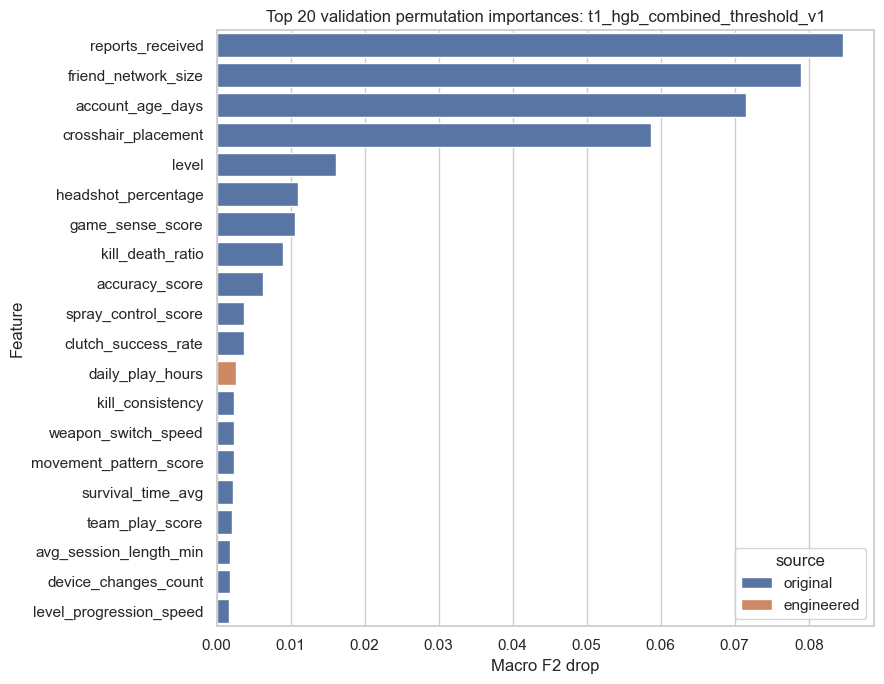

In [22]:
round1_model, round1_dataset, round1_pred = show_diagnostics(round1_winner)
round1_importance = show_feature_importance(round1_winner)

In [23]:
diagnostics = pd.DataFrame({
    "true": y_valid.to_numpy(), "pred": round1_pred,
    "missing_original": original_train.iloc[valid_idx][original_test.columns.drop(ID)].isna().sum(axis=1).to_numpy(),
    "account_age_days": original_train.iloc[valid_idx]["account_age_days"].to_numpy(),
})
diagnostics["correct"] = diagnostics.true == diagnostics.pred
diagnostics["missing_group"] = pd.cut(diagnostics.missing_original, bins=[-1, 0, 3, 6, 31],
                                      labels=["0", "1–3", "4–6", "7+"])
display(diagnostics.groupby("missing_group", observed=True).agg(
    rows=("correct", "size"), accuracy=("correct", "mean"),
    cheater_rate=("true", "mean")).round(3))
display(diagnostics.groupby(pd.qcut(diagnostics.account_age_days, 4, duplicates="drop"),
                            observed=True).agg(
    rows=("correct", "size"), accuracy=("correct", "mean"),
    cheater_rate=("true", "mean")).round(3))

,rows,accuracy,cheater_rate
missing_group,,,
0,303,0.815,0.363
1–3,8404,0.803,0.336
4–6,8299,0.780,0.359
7+,1158,0.759,0.377


,rows,accuracy,cheater_rate
account_age_days,,,
"(1.0970000000000002, 156.989]",3879,0.902,0.357
"(156.989, 476.247]",3878,0.737,0.403
"(476.247, 764.216]",3878,0.720,0.349
"(764.216, 1499.65]",3878,0.827,0.287


### Round 1 finding

The strongest scikit-learn result is thresholded combined HGB (**0.7768**). At baseline settings, engineered features did not improve the three model families. With matched HGB settings, combined features improved macro F₂ by about **0.0037**, while the matched random forest did worse. Threshold choice matters more than this feature-set difference.

## 3. Round 2 — LightGBM, XGBoost, and CatBoost

In [24]:
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import lightgbm, xgboost, catboost, sklearn

display(pd.Series({"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                   "xgboost": xgboost.__version__, "catboost": catboost.__version__},
                  name="version").to_frame())

def lightgbm_baseline():
    return LGBMClassifier(n_estimators=300, learning_rate=.05, num_leaves=31,
                          min_child_samples=30, reg_lambda=1.0, verbosity=-1,
                          n_jobs=4, random_state=SEED)

def xgboost_baseline():
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=.05,
                         subsample=.85, colsample_bytree=.85, reg_lambda=2.0,
                         tree_method="hist", eval_metric="logloss", n_jobs=4,
                         random_state=SEED)

def catboost_baseline():
    return CatBoostClassifier(iterations=500, depth=6, learning_rate=.05,
                              l2_leaf_reg=3.0, loss_function="Logloss",
                              verbose=False, thread_count=4, random_seed=SEED,
                              allow_writing_files=False)

,version
scikit-learn,1.8.0
lightgbm,4.7.0
xgboost,3.2.0
catboost,1.2.10


### Try each library on original and combined features

In [25]:
name = "t1_lgbm_original_v1"
if saved_result(name, "original") is None:
    model = lightgbm_baseline()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "LightGBM original features")

Loaded t1_lgbm_original_v1: macro F2 = 0.75492


In [26]:
name = "t1_lgbm_combined_v1"
if saved_result(name, "combined") is None:
    model = lightgbm_baseline()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "LightGBM combined features")

Loaded t1_lgbm_combined_v1: macro F2 = 0.75252


In [27]:
name = "t1_xgb_original_v1"
if saved_result(name, "original") is None:
    model = xgboost_baseline()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "XGBoost original features")

Loaded t1_xgb_original_v1: macro F2 = 0.74583


In [28]:
name = "t1_xgb_combined_v1"
if saved_result(name, "combined") is None:
    model = xgboost_baseline()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "XGBoost combined features")

Loaded t1_xgb_combined_v1: macro F2 = 0.74912


In [29]:
name = "t1_cat_original_v1"
if saved_result(name, "original") is None:
    model = catboost_baseline()
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "CatBoost original features")

Loaded t1_cat_original_v1: macro F2 = 0.75216


In [30]:
name = "t1_cat_combined_v1"
if saved_result(name, "combined") is None:
    model = catboost_baseline()
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "CatBoost combined features")

Loaded t1_cat_combined_v1: macro F2 = 0.75356


### Search promising settings

In [31]:
lgbm_params = {
    "n_estimators": [250, 450, 700], "learning_rate": [.03, .05, .08],
    "num_leaves": [15, 31, 63], "min_child_samples": [20, 50, 100],
    "max_depth": [-1, 6, 10], "reg_lambda": [0.0, 1.0, 5.0],
}
xgb_params = {
    "n_estimators": [250, 450, 700], "max_depth": [3, 5, 7],
    "learning_rate": [.03, .05, .08], "min_child_weight": [1, 5, 10],
    "subsample": [.75, .9, 1.0], "colsample_bytree": [.75, .9, 1.0],
    "reg_lambda": [1.0, 3.0, 8.0],
}
cat_params = {
    "iterations": [350, 550, 800], "depth": [4, 6, 8],
    "learning_rate": [.03, .06, .10], "l2_leaf_reg": [2.0, 5.0, 10.0],
    "random_strength": [0.0, 1.0, 2.0],
}

In [32]:
name = "t1_lgbm_original_tuned_v1"
if saved_result(name, "original") is None:
    search = RandomizedSearchCV(
        estimator=lightgbm_baseline(), param_distributions=lgbm_params,
        n_iter=6, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev["original"], y_dev)
    print("Best development CV macro F2:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    record_model(name, "original", search.best_estimator_, "Development CV LightGBM search",
                 tuning={"cv": "3-fold stratified", "searches": 6,
                         "best_params": search.best_params_,
                         "best_cv_macro_F2": search.best_score_})

Loaded t1_lgbm_original_tuned_v1: macro F2 = 0.75770


In [33]:
name = "t1_xgb_combined_tuned_v1"
if saved_result(name, "combined") is None:
    search = RandomizedSearchCV(
        estimator=xgboost_baseline(), param_distributions=xgb_params,
        n_iter=5, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev["combined"], y_dev)
    print("Best development CV macro F2:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    record_model(name, "combined", search.best_estimator_, "Development CV XGBoost search",
                 tuning={"cv": "3-fold stratified", "searches": 5,
                         "best_params": search.best_params_,
                         "best_cv_macro_F2": search.best_score_})

Loaded t1_xgb_combined_tuned_v1: macro F2 = 0.75512


In [34]:
name = "t1_cat_combined_tuned_v1"
if saved_result(name, "combined") is None:
    search = RandomizedSearchCV(
        estimator=catboost_baseline(), param_distributions=cat_params,
        n_iter=5, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev["combined"], y_dev)
    print("Best development CV macro F2:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    record_model(name, "combined", search.best_estimator_, "Development CV CatBoost search",
                 tuning={"cv": "3-fold stratified", "searches": 5,
                         "best_params": search.best_params_,
                         "best_cv_macro_F2": search.best_score_})

Loaded t1_cat_combined_tuned_v1: macro F2 = 0.75315


### Tune decision thresholds

In [35]:
name = "t1_lgbm_original_threshold_v1"
if saved_result(name, "original") is None:
    base_model = clone(load_model("t1_lgbm_original_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["original"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "original", threshold_model,
                 "Development CV threshold on original features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_lgbm_original_tuned_v1"})

Loaded t1_lgbm_original_threshold_v1: macro F2 = 0.77762


In [36]:
name = "t1_xgb_combined_threshold_v1"
if saved_result(name, "combined") is None:
    base_model = clone(load_model("t1_xgb_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["combined"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "combined", threshold_model,
                 "Development CV threshold on combined features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_xgb_combined_tuned_v1"})

Loaded t1_xgb_combined_threshold_v1: macro F2 = 0.77530


In [37]:
name = "t1_cat_combined_threshold_v1"
if saved_result(name, "combined") is None:
    base_model = clone(load_model("t1_cat_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["combined"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "combined", threshold_model,
                 "Development CV threshold on combined features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_cat_combined_tuned_v1"})

Loaded t1_cat_combined_threshold_v1: macro F2 = 0.77318


### Check the same tuned settings on the other feature set

In [38]:
name = "t1_lgbm_combined_matched_v1"
if saved_result(name, "combined") is None:
    model = clone(load_model("t1_lgbm_original_tuned_v1"))
    model.fit(X_dev["combined"], y_dev)
    record_model(name, "combined", model, "LightGBM with matched settings on combined features",
                 tuning={"parameter_source": "t1_lgbm_original_tuned_v1",
                         "cv": "source model's development CV"})

Loaded t1_lgbm_combined_matched_v1: macro F2 = 0.75674


In [39]:
name = "t1_lgbm_combined_matched_threshold_v1"
if saved_result(name, "combined") is None:
    base_model = clone(load_model("t1_lgbm_original_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["combined"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "combined", threshold_model,
                 "Development CV threshold on combined features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_lgbm_original_tuned_v1"})

Loaded t1_lgbm_combined_matched_threshold_v1: macro F2 = 0.77847


In [40]:
name = "t1_xgb_original_matched_v1"
if saved_result(name, "original") is None:
    model = clone(load_model("t1_xgb_combined_tuned_v1"))
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "XGBoost with matched settings on original features",
                 tuning={"parameter_source": "t1_xgb_combined_tuned_v1",
                         "cv": "source model's development CV"})

Loaded t1_xgb_original_matched_v1: macro F2 = 0.75641


In [41]:
name = "t1_xgb_original_matched_threshold_v1"
if saved_result(name, "original") is None:
    base_model = clone(load_model("t1_xgb_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["original"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "original", threshold_model,
                 "Development CV threshold on original features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_xgb_combined_tuned_v1"})

Loaded t1_xgb_original_matched_threshold_v1: macro F2 = 0.77420


In [42]:
name = "t1_cat_original_matched_v1"
if saved_result(name, "original") is None:
    model = clone(load_model("t1_cat_combined_tuned_v1"))
    model.fit(X_dev["original"], y_dev)
    record_model(name, "original", model, "CatBoost with matched settings on original features",
                 tuning={"parameter_source": "t1_cat_combined_tuned_v1",
                         "cv": "source model's development CV"})

Loaded t1_cat_original_matched_v1: macro F2 = 0.75086


In [43]:
name = "t1_cat_original_matched_threshold_v1"
if saved_result(name, "original") is None:
    base_model = clone(load_model("t1_cat_combined_tuned_v1"))
    threshold_model = TunedThresholdClassifierCV(
        estimator=base_model, scoring=SCORE,
        thresholds=np.linspace(0.10, 0.90, 33), cv=CV,
        refit=True, n_jobs=1, store_cv_results=True,
    )
    threshold_model.fit(X_dev["original"], y_dev)
    print("Development CV threshold:", round(threshold_model.best_threshold_, 4))
    print("Development CV macro F2:", round(threshold_model.best_score_, 5))
    record_model(name, "original", threshold_model,
                 "Development CV threshold on original features",
                 tuning={"cv": "3-fold stratified",
                         "threshold": threshold_model.best_threshold_,
                         "best_cv_macro_F2": threshold_model.best_score_,
                         "parameter_source": "t1_cat_combined_tuned_v1"})

Loaded t1_cat_original_matched_threshold_v1: macro F2 = 0.77267


### Compare both rounds and inspect the current winner

,name,dataset,macro_F2
0,t1_lgbm_combined_matched_threshold_v1,eda_combined_v1,0.7785
1,t1_lgbm_original_threshold_v1,eda_original_v1,0.7776
2,t1_hgb_combined_threshold_v1,eda_combined_v1,0.7768
3,t1_xgb_combined_threshold_v1,eda_combined_v1,0.7753
4,t1_xgb_original_matched_threshold_v1,eda_original_v1,0.7742
5,t1_cat_combined_threshold_v1,eda_combined_v1,0.7732
6,t1_hgb_original_threshold_v1,eda_original_v1,0.7732
7,t1_cat_original_matched_threshold_v1,eda_original_v1,0.7727
8,t1_rf_original_matched_v1,eda_original_v1,0.7708
9,t1_rf_combined_tuned_v1,eda_combined_v1,0.7668


Best in this round: t1_lgbm_combined_matched_threshold_v1 (0.77847)


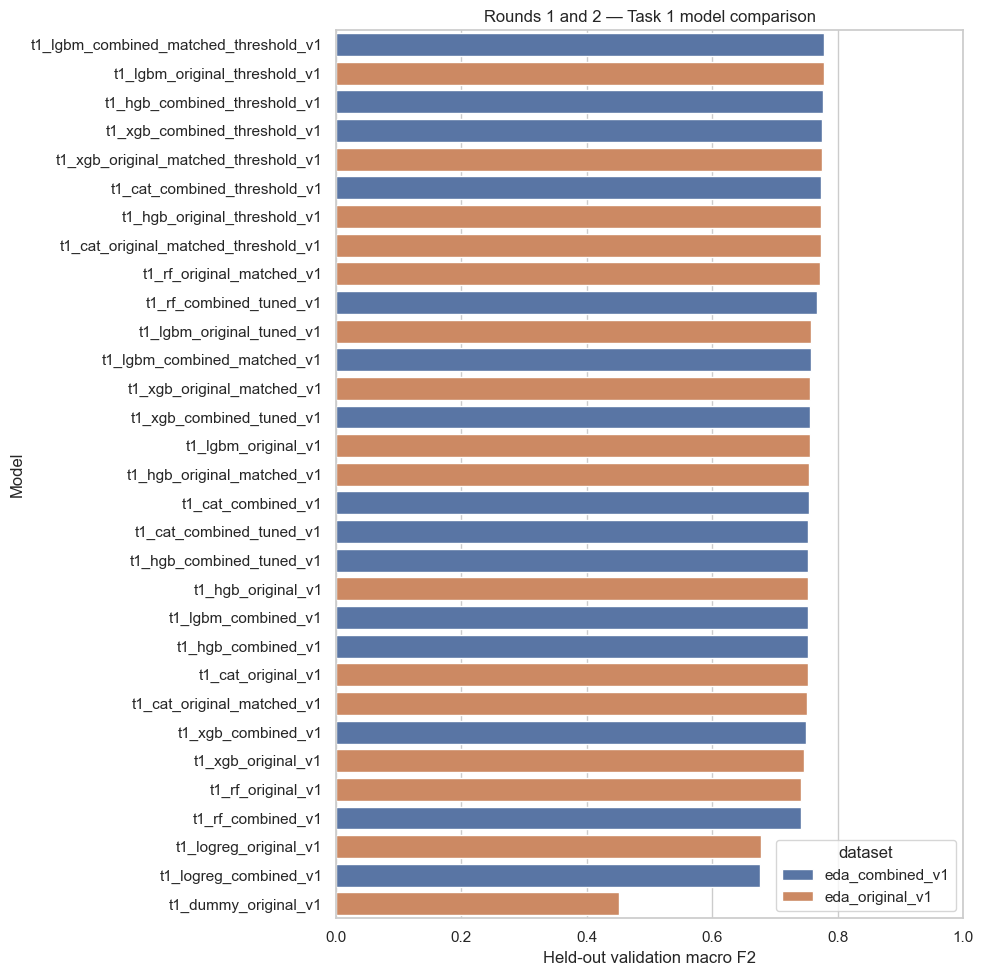

In [44]:
round2_names = [
    "t1_lgbm_original_v1", "t1_lgbm_combined_v1",
    "t1_xgb_original_v1", "t1_xgb_combined_v1",
    "t1_cat_original_v1", "t1_cat_combined_v1",
    "t1_lgbm_original_tuned_v1", "t1_xgb_combined_tuned_v1",
    "t1_cat_combined_tuned_v1",
    "t1_lgbm_original_threshold_v1", "t1_xgb_combined_threshold_v1",
    "t1_cat_combined_threshold_v1",
    "t1_lgbm_combined_matched_v1", "t1_lgbm_combined_matched_threshold_v1",
    "t1_xgb_original_matched_v1", "t1_xgb_original_matched_threshold_v1",
    "t1_cat_original_matched_v1", "t1_cat_original_matched_threshold_v1",
]
round2_ranking = show_rankings(round1_names + round2_names,
                               "Rounds 1 and 2 — Task 1 model comparison")
round2_winner = round2_ranking.iloc[0]["name"]

Model: t1_lgbm_combined_matched_threshold_v1
Validation macro F2: 0.77847
F2 legitimate: 0.79909
F2 cheater: 0.75785
Threshold: 0.375
              precision    recall  f1-score   support

  Legitimate     0.8725    0.7826    0.8251     11819
     Cheater     0.6603    0.7869    0.7181      6345

    accuracy                         0.7841     18164
   macro avg     0.7664    0.7848    0.7716     18164
weighted avg     0.7984    0.7841    0.7877     18164



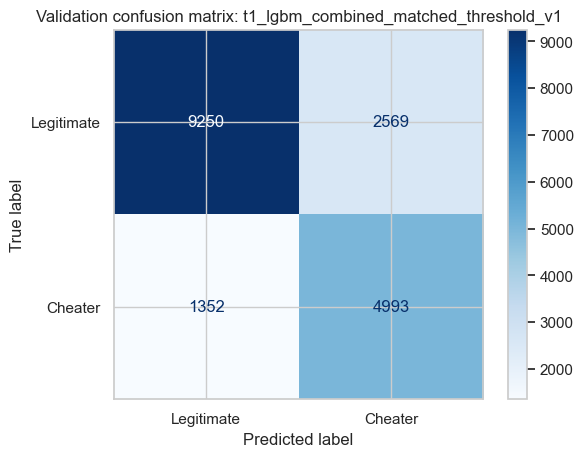

ROC AUC: 0.8885
Average precision (cheater): 0.8296


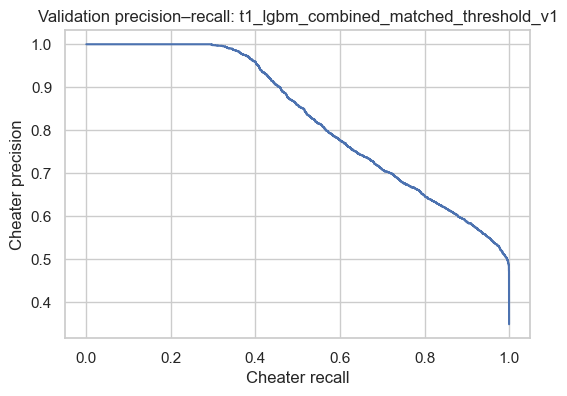

Loaded permutation importance: t1_lgbm_combined_matched_threshold_v1


,feature,macro_F2_drop,std,source
0,reports_received,0.0911,0.0015,original
1,friend_network_size,0.0804,0.0053,original
2,account_age_days,0.0705,0.0005,original
3,crosshair_placement,0.0578,0.0021,original
4,game_sense_score,0.0180,0.0018,original
5,headshot_percentage,0.0172,0.0019,original
6,level,0.0159,0.0008,original
7,kill_death_ratio,0.0149,0.0019,original
8,accuracy_score,0.0090,0.0017,original
9,kill_consistency,0.0082,0.0018,original


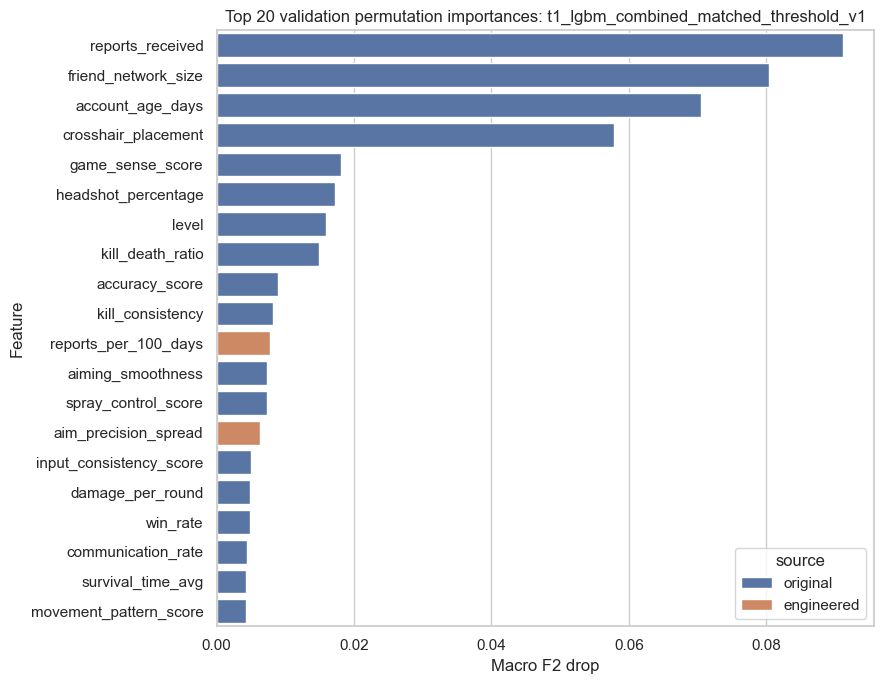

In [45]:
round2_model, round2_dataset, round2_pred = show_diagnostics(round2_winner)
round2_importance = show_feature_importance(round2_winner)

In [46]:
final_test = datasets[round2_dataset][2].drop(columns=[ID])
final_test_pred = np.asarray(round2_model.predict(final_test)).reshape(-1)
assert len(final_test_pred) == len(final_test) == 25889
assert set(np.unique(final_test_pred)) <= {0, 1}
print("Saved model test inference:", len(final_test_pred), "rows")
print("Selected saved model:", round2_winner)

Saved model test inference: 25889 rows
Selected saved model: t1_lgbm_combined_matched_threshold_v1


### Final findings and next step

- Best held-out macro F₂: **0.77847**, `t1_lgbm_combined_matched_threshold_v1`, with a development-CV threshold of **0.375**. Its class F₂ values are **0.79909** (legitimate) and **0.75785** (cheater).
- The next LightGBM original model scores **0.77762**. The difference of **0.00085** on one holdout does not establish a robust feature-engineering gain.
- The largest validation permutation drops are for `reports_received`, `friend_network_size`, `account_age_days`, and `crosshair_placement`. This measures model reliance, not causation.
- The holdout informed selection among many models. Round 3 below compares a short list on repeated folds, tests a smaller feature set, and then trains the selected procedure on every labeled row under a new artifact name.

## 4. Round 3 — stability and feature ablation

The first two rounds used one holdout to choose among many models. Here we compare three finalists on **the same six outer folds** (3 folds × 2 repeats). Each outer training fold uses its own 3-fold CV to choose the decision threshold. The outer fold is used only for scoring.

These are more useful stability checks than another score on the original holdout, but they are still exploratory: the finalists were chosen after looking at that holdout. Test labels are never used.

In [47]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

ROUND3_REMOVED = [
    "account_age_days_missing", "reports_received_missing",
    "avg_session_length_min_missing", "aiming_smoothness_missing",
    "aim_precision_observed", "missing_feature_count", "map_knowledge",
]
combined_features = X_dev["combined"].columns.tolist()
assert len(combined_features) == 45
assert set(ROUND3_REMOVED) <= set(combined_features)
pruned_features = [column for column in combined_features if column not in ROUND3_REMOVED]
assert len(pruned_features) == 38
print("Pruned feature count:", len(pruned_features), "of", len(combined_features))
print("Removed:", ROUND3_REMOVED)

outer_cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=SEED)
outer_splits = list(outer_cv.split(original_train[original_test.columns.drop(ID)], y))
assert len(outer_splits) == 6

def round3_estimator(source_name, selected_features=None):
    base = clone(load_model(source_name))
    if selected_features is None:
        return base
    selector = ColumnTransformer(
        [("keep", "passthrough", selected_features)], remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("select_features", selector), ("classifier", base)])

def run_outer_cv(label, dataset, source_name, selected_features=None):
    # Resume completed folds from saved analysis results; never fit on outer validation rows.
    train_card = datasets[dataset][0]
    train_path = SRC / train_card["splits"]["train"]["path"]
    source_path = model_paths(source_name)[0]
    source_card = json.loads(model_paths(source_name)[1].read_text(encoding="utf-8"))
    cache_path = SRC / "task1" / "models" / "results" / f"round3_{label}_cv6.json"
    cache_key = {
        "seed": SEED, "outer": "3-fold x 2 repeats", "inner": "3-fold threshold CV",
        "source": source_name, "source_created_at": source_card["created_at"],
        "source_bytes": source_path.stat().st_size,
        "data_name": train_card["name"], "data_created_at": train_card["created_at"],
        "train_bytes": train_path.stat().st_size,
        "selected_features": selected_features,
    }
    cached = json.loads(cache_path.read_text(encoding="utf-8")) if cache_path.exists() else None
    if cached is not None and cached.get("key") != cache_key:
        raise ValueError(f"Stale Round 3 cache: {cache_path}; use a new experiment name")
    rows = cached["folds"] if cached is not None else []
    X = datasets[dataset][1][datasets[dataset][2].columns.drop(ID).tolist()]
    for fold, (train_rows, valid_rows) in enumerate(outer_splits, start=1):
        if fold <= len(rows):
            continue
        model = TunedThresholdClassifierCV(
            estimator=round3_estimator(source_name, selected_features),
            scoring=SCORE, thresholds=np.linspace(0.10, 0.90, 33),
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
            refit=True, n_jobs=1,
        )
        model.fit(X.iloc[train_rows], y.iloc[train_rows])
        pred = np.asarray(model.predict(X.iloc[valid_rows])).reshape(-1)
        row = {
            "model": label, "fold": fold, "threshold": float(model.best_threshold_),
            "macro_F2": float(fbeta_score(y.iloc[valid_rows], pred, beta=2,
                                           average="macro", zero_division=0)),
            "F2_legitimate": float(fbeta_score(y.iloc[valid_rows], pred, beta=2,
                                                pos_label=0, zero_division=0)),
            "F2_cheater": float(fbeta_score(y.iloc[valid_rows], pred, beta=2,
                                             pos_label=1, zero_division=0)),
            "train_rows": len(train_rows), "valid_rows": len(valid_rows),
        }
        rows.append(row)
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        cache_path.write_text(json.dumps({"key": cache_key, "folds": rows}, indent=2),
                              encoding="utf-8")
        print(label, "fold", fold, "macro F2", round(row["macro_F2"], 5),
              "threshold", round(row["threshold"], 3))
    if len(rows) == len(outer_splits):
        print(label, ": loaded/completed all", len(rows), "outer folds")
    return pd.DataFrame(rows)

Pruned feature count: 38 of 45
Removed: ['account_age_days_missing', 'reports_received_missing', 'avg_session_length_min_missing', 'aiming_smoothness_missing', 'aim_precision_observed', 'missing_feature_count', 'map_knowledge']


### Compare the three finalists on the same folds

In [48]:
round3_lgbm_combined = run_outer_cv(
    "lgbm_combined", "combined", "t1_lgbm_original_tuned_v1"
)

lgbm_combined : loaded/completed all 6 outer folds


In [49]:
round3_lgbm_original = run_outer_cv(
    "lgbm_original", "original", "t1_lgbm_original_tuned_v1"
)

lgbm_original : loaded/completed all 6 outer folds


In [50]:
round3_hgb_combined = run_outer_cv(
    "hgb_combined", "combined", "t1_hgb_combined_tuned_v1"
)

hgb_combined : loaded/completed all 6 outer folds


### Test a smaller feature set

The seven removed columns had the smallest permutation-importance drops for the Round 2 winner. This ranking came from the previously inspected holdout, so the pruning idea is exploratory. The selector stays **inside the saved pipeline** so the model accepts the full combined test schema at inference time.

In [51]:
round3_lgbm_pruned = run_outer_cv(
    "lgbm_combined_pruned", "combined", "t1_lgbm_original_tuned_v1",
    selected_features=pruned_features,
)

lgbm_combined_pruned

 : loaded/completed all 6 outer folds


### Compare paired fold scores and threshold stability

,model,mean_macro_F2,std_macro_F2,min_macro_F2,mean_F2_cheater,mean_threshold,min_threshold,max_threshold
0,lgbm_combined_pruned,0.77733,0.00127,0.77484,0.74719,0.38750,0.375,0.4
1,lgbm_combined,0.77679,0.00130,0.77541,0.75347,0.37917,0.375,0.4
2,lgbm_original,0.77676,0.00051,0.77603,0.74601,0.38750,0.375,0.4
3,hgb_combined,0.77536,0.00110,0.77401,0.75309,0.37500,0.350,0.4


model,hgb_combined,lgbm_combined,lgbm_combined_pruned,lgbm_original
fold,,,,
1,0.77637,0.77887,0.77831,0.77720
2,0.77430,0.77579,0.77765,0.77648
3,0.77669,0.77630,0.77723,0.77675
4,0.77401,0.77541,0.77484,0.77603
5,0.77579,0.77779,0.77799,0.77664
6,0.77501,0.77659,0.77795,0.77744


Pruned minus full LightGBM, mean paired delta: 0.00054


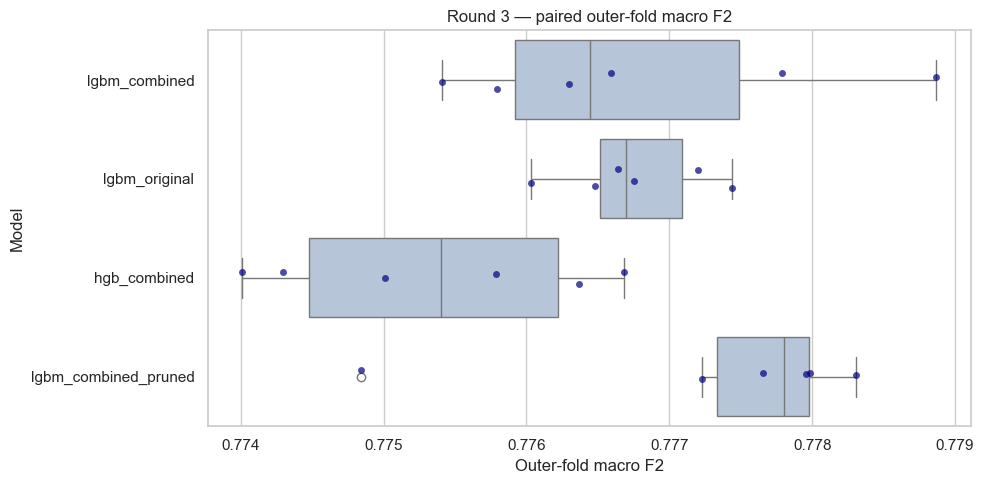

In [52]:
round3_folds = pd.concat([
    round3_lgbm_combined, round3_lgbm_original,
    round3_hgb_combined, round3_lgbm_pruned,
], ignore_index=True)
round3_summary = (round3_folds.groupby("model", as_index=False)
                  .agg(mean_macro_F2=("macro_F2", "mean"),
                       std_macro_F2=("macro_F2", "std"),
                       min_macro_F2=("macro_F2", "min"),
                       mean_F2_cheater=("F2_cheater", "mean"),
                       mean_threshold=("threshold", "mean"),
                       min_threshold=("threshold", "min"),
                       max_threshold=("threshold", "max"))
                  .sort_values("mean_macro_F2", ascending=False).reset_index(drop=True))
display(round3_summary.round(5))

paired = round3_folds.pivot(index="fold", columns="model", values="macro_F2")
display(paired.round(5))
print("Pruned minus full LightGBM, mean paired delta:",
      round((paired["lgbm_combined_pruned"] - paired["lgbm_combined"]).mean(), 5))

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=round3_folds, x="macro_F2", y="model", ax=ax, color="lightsteelblue")
sns.stripplot(data=round3_folds, x="macro_F2", y="model", ax=ax,
              color="navy", alpha=0.7, size=5)
ax.set(title="Round 3 — paired outer-fold macro F2", xlabel="Outer-fold macro F2", ylabel="Model")
plt.tight_layout()
plt.show()

### Fit the selected procedure on every labeled row

Pick the highest mean outer-fold macro F₂. This comparison is exploratory because the candidate list was informed by earlier holdout results. The full-data model gets a **new name**. Its evaluation card records the outer-CV estimate under a distinct metric name; it is not a fresh holdout score for the full-data fit.

In [53]:
round3_choice = round3_summary.iloc[0]["model"]
round3_specs = {
    "lgbm_combined": ("combined", "t1_lgbm_original_tuned_v1", None),
    "lgbm_original": ("original", "t1_lgbm_original_tuned_v1", None),
    "hgb_combined": ("combined", "t1_hgb_combined_tuned_v1", None),
    "lgbm_combined_pruned": ("combined", "t1_lgbm_original_tuned_v1", pruned_features),
}
final_dataset, final_source, final_features = round3_specs[round3_choice]
final_name = f"t1_{round3_choice}_cv6_full_v1"
final_model_path, final_card_path, final_eval_path = model_paths(final_name)
final_X = datasets[final_dataset][1][datasets[final_dataset][2].columns.drop(ID).tolist()]
assert len(final_X) == len(y) == 90816

if final_model_path.exists() != final_card_path.exists():
    raise RuntimeError(f"Incomplete final model artifact for {final_name}")
if final_model_path.exists():
    final_model = load_model(final_name)
    final_card = json.loads(final_card_path.read_text(encoding="utf-8"))
    if final_card["data_name"] != datasets[final_dataset][0]["name"]:
        raise ValueError("Saved final model is linked to a different dataset")
    print("Loaded final model:", final_name)
else:
    final_model = TunedThresholdClassifierCV(
        estimator=round3_estimator(final_source, final_features),
        scoring=SCORE, thresholds=np.linspace(0.10, 0.90, 33),
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
        refit=True, n_jobs=1,
    )
    final_model.fit(final_X, y)
    save_model(
        task=1, name=final_name, model=final_model,
        data_name=datasets[final_dataset][0]["name"],
        card={"idea": "Round 3 selected model refit on all 90,816 labeled rows",
              "source_model": final_source, "outer_cv": "3-fold x 2 repeats",
              "outer_cv_mean_macro_F2": float(round3_summary.iloc[0]["mean_macro_F2"]),
              "selected_features": final_features or "all",
              "threshold": float(final_model.best_threshold_), "seed": SEED},
    )
    print("Saved full-data model:", final_name)
print("Full-data CV threshold:", round(final_model.best_threshold_, 5))

if final_eval_path.exists():
    final_evaluation = json.loads(final_eval_path.read_text(encoding="utf-8"))
    assert final_evaluation["metric"] == "macro_F2_outer_cv6"
    print("Loaded outer-CV evaluation:", round(final_evaluation["score"], 5))
else:
    chosen_folds = round3_folds.loc[round3_folds.model == round3_choice]
    final_evaluation = evaluate_model(
        task=1, name=final_name,
        score=float(chosen_folds.macro_F2.mean()),
        metric_name="macro_F2_outer_cv6", higher_is_better=True,
        card={"method": "3-fold x 2 repeats; threshold chosen by inner 3-fold CV",
              "note": "CV estimate of the selected procedure, not a holdout score of the full-data fit",
              "fold_scores": chosen_folds.macro_F2.round(6).tolist(),
              "seed": SEED},
    )
    print("Recorded outer-CV estimate:", round(final_evaluation["score"], 5))

Loaded final model:

 t1_lgbm_combined_pruned_cv6_full_v1
Full-data CV threshold: 0.4
Loaded outer-CV evaluation: 0.77733


### Build a Task 1 submission draft from that saved full-data model

In [54]:
from src.pipeline.build_sample_submission import build_sample_submission

submission_name = "t1_round3_full_v1"
submission_dir = SRC / "task1" / "submission"
submission_csv = submission_dir / f"{submission_name}.csv"
submission_card_path = submission_dir / f"{submission_name}.json"
if submission_csv.exists() != submission_card_path.exists():
    raise RuntimeError(f"Incomplete submission artifact for {submission_name}")
if submission_csv.exists():
    submission_card = json.loads(submission_card_path.read_text(encoding="utf-8"))
    if submission_card["model_name"] != final_name:
        raise ValueError("Existing submission uses a different model; choose a new submission name")
    print("Loaded Task 1 submission:", submission_csv)
else:
    submission_card = build_sample_submission(
        task=1, name=submission_name, model_name=final_name, id_column=ID,
        card={"source": final_name,
              "selection": "Highest mean macro F2 in Round 3 outer CV"},
    )
    print("Saved Task 1 submission:", SRC / submission_card["submission_path"])

submission = pd.read_csv(submission_csv, sep="|")
assert submission.columns.tolist() == ["id", "task1"]
assert len(submission) == 25889 and submission["id"].is_unique
assert set(submission["task1"].unique()) <= {0, 1}
print("Submission rows:", len(submission))
print("Predicted cheater rate:", round(submission["task1"].mean(), 4))

Loaded Task 1 submission: C:\Users\BTCOM\Desktop\ml-final\src\task1\submission\t1_round3_full_v1.csv
Submission rows: 25889
Predicted cheater rate: 0.3841


### Round 3 findings

+- Across six paired outer folds, mean macro F₂ was **0.77733** for LightGBM with 38 features, **0.77679** for LightGBM with all 45 combined features, **0.77676** for LightGBM with 31 original features, and **0.77536** for HGB with 45 features.
+- The pruned LightGBM gained **0.00054** over the full combined version on average and won 4 of 6 paired folds. This is a small exploratory difference; the original-feature LightGBM had the lowest fold-to-fold standard deviation.
+- The selected pruned procedure was refitted on all **90,816** labeled rows. Its full-data CV threshold is **0.400**. The saved evaluation under `macro_F2_outer_cv6` describes the outer-CV procedure estimate, not a fresh holdout score for the full-data fit.
+- The Task 1 submission draft contains **25,889** rows. Test data was used only to produce those predictions and check their format.

## 5. Round 4 — is more Task 1 work worth it?

Round 3 showed stable absolute scores but only a small gap between the top LightGBM variants. To decide whether another feature or tuning round is worthwhile, inspect **out-of-fold predictions** on the first three Round 3 outer folds. The pruned and original LightGBM models use identical folds; each threshold is chosen by inner CV on that fold's training rows. Test is not used.

We will inspect paired errors, a prespecified 50/50 probability blend, error slices, and the optimistic upper bound from retuning a threshold on each outer validation fold. A blend improvement around **0.002 macro F₂** across most folds, or a large actionable error slice, would justify another focused experiment. These are decision heuristics, not statistical significance tests.

### Collect out-of-fold predictions for the two LightGBM variants

In [55]:
round4_splits = outer_splits[:3]
assert len(round4_splits) == 3
assert np.array_equal(np.sort(np.concatenate([valid for _, valid in round4_splits])),
                      np.arange(len(y)))

def collect_round4_oof(label, dataset, source_name, selected_features=None, repeat=1):
    result_dir = SRC / "task1" / "models" / "results"
    suffix = "" if repeat == 1 else f"_repeat{repeat}"
    oof_path = result_dir / f"round4_{label}{suffix}_oof_v1.parquet"
    card_path = result_dir / f"round4_{label}{suffix}_oof_v1.json"
    data_card = datasets[dataset][0]
    source_card = json.loads(model_paths(source_name)[1].read_text(encoding="utf-8"))
    key = {
        "seed": SEED, "outer": f"{'first' if repeat == 1 else 'second'} repeat of Round 3 3-fold CV",
        "inner": "3-fold threshold CV", "source": source_name,
        "source_created_at": source_card["created_at"],
        "data_name": data_card["name"], "data_created_at": data_card["created_at"],
        "selected_features": selected_features,
    }
    if oof_path.exists() != card_path.exists():
        raise RuntimeError(f"Incomplete Round 4 OOF artifact for {label}")
    if oof_path.exists():
        saved = json.loads(card_path.read_text(encoding="utf-8"))
        if saved["key"] != key:
            raise ValueError(f"Round 4 OOF artifact has different lineage: {oof_path}")
        frame = pd.read_parquet(oof_path)
        print("Loaded", label, "OOF predictions:", len(frame), "rows")
    else:
        full_train = datasets[dataset][1]
        X = full_train[datasets[dataset][2].columns.drop(ID).tolist()]
        rows = []
        splits = outer_splits[(repeat-1)*3:repeat*3]
        assert len(splits) == 3
        for fold, (train_rows, valid_rows) in enumerate(splits, start=(repeat-1)*3+1):
            model = TunedThresholdClassifierCV(
                estimator=round3_estimator(source_name, selected_features),
                scoring=SCORE, thresholds=np.linspace(0.10, 0.90, 33),
                cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
                refit=True, n_jobs=1,
            )
            model.fit(X.iloc[train_rows], y.iloc[train_rows])
            valid_X = X.iloc[valid_rows]
            prob = np.asarray(model.predict_proba(valid_X))[:, 1]
            pred = np.asarray(model.predict(valid_X)).reshape(-1)
            rows.append(pd.DataFrame({
                "row_index": valid_rows, "player_id": full_train.iloc[valid_rows][ID].to_numpy(),
                "true": y.iloc[valid_rows].to_numpy(), "prob": prob,
                "pred": pred, "threshold": float(model.best_threshold_),
                "fold": fold, "model": label,
            }))
            print(label, "fold", fold, "macro F2",
                  round(fbeta_score(y.iloc[valid_rows], pred, beta=2,
                                    average="macro", zero_division=0), 5))
        frame = pd.concat(rows, ignore_index=True).sort_values("row_index").reset_index(drop=True)
        assert frame.row_index.is_unique and len(frame) == len(y)
        result_dir.mkdir(parents=True, exist_ok=True)
        frame.to_parquet(oof_path, index=False)
        card_path.write_text(json.dumps({"key": key, "rows": len(frame),
                                         "columns": frame.columns.tolist()}, indent=2),
                             encoding="utf-8")
        print("Saved", label, "OOF predictions:", oof_path)
    assert frame.row_index.is_unique and len(frame) == len(y)
    assert frame["row_index"].between(0, len(y)-1).all()
    assert np.array_equal(frame.sort_values("row_index")["true"].to_numpy(), y.to_numpy())
    return frame

In [56]:
round4_pruned = collect_round4_oof(
    "lgbm_combined_pruned", "combined", "t1_lgbm_original_tuned_v1",
    selected_features=pruned_features,
)

Loaded lgbm_combined_pruned OOF predictions: 90816 rows


In [57]:
round4_original = collect_round4_oof(
    "lgbm_original", "original", "t1_lgbm_original_tuned_v1",
)

Loaded

 lgbm_original OOF predictions: 90816 rows


### Pair predictions and check score agreement with Round 3

In [58]:
paired_oof = round4_pruned.merge(
    round4_original, on="row_index", suffixes=("_pruned", "_original"),
    validate="one_to_one",
)
assert paired_oof["player_id_pruned"].equals(paired_oof["player_id_original"])
assert paired_oof["true_pruned"].equals(paired_oof["true_original"])
assert paired_oof["fold_pruned"].equals(paired_oof["fold_original"])

round4_scores = []
for fold, group in paired_oof.groupby("fold_pruned", sort=True):
    for variant in ["pruned", "original"]:
        score = fbeta_score(group["true_pruned"], group[f"pred_{variant}"],
                            beta=2, average="macro", zero_division=0)
        round4_scores.append({"fold": fold, "model": variant, "macro_F2": score})
        source = (round3_lgbm_pruned if variant == "pruned" else round3_lgbm_original)
        expected = source.loc[source.fold == fold, "macro_F2"].iloc[0]
        assert abs(score - expected) < 1e-12
round4_scores = pd.DataFrame(round4_scores)
display(round4_scores.pivot(index="fold", columns="model", values="macro_F2").round(5))
print("OOF rows with both models:", len(paired_oof))

model,original,pruned
fold,,
1,0.77720,0.77831
2,0.77648,0.77765
3,0.77675,0.77723


OOF rows with both models: 90816


### Measure error overlap and a fixed 50/50 blend

In [59]:
paired_oof["wrong_pruned"] = paired_oof.pred_pruned != paired_oof.true_pruned
paired_oof["wrong_original"] = paired_oof.pred_original != paired_oof.true_pruned
error_overlap = pd.Series({
    "both_correct": (~paired_oof.wrong_pruned & ~paired_oof.wrong_original).sum(),
    "both_wrong": (paired_oof.wrong_pruned & paired_oof.wrong_original).sum(),
    "pruned_only_wrong": (paired_oof.wrong_pruned & ~paired_oof.wrong_original).sum(),
    "original_only_wrong": (~paired_oof.wrong_pruned & paired_oof.wrong_original).sum(),
}, name="accounts")
display(error_overlap.to_frame())

# Fixed before looking at the OOF scores: equal-weight probabilities and mean inner-CV threshold.
paired_oof["blend_prob"] = (paired_oof.prob_pruned + paired_oof.prob_original) / 2
paired_oof["blend_threshold"] = (paired_oof.threshold_pruned + paired_oof.threshold_original) / 2
paired_oof["blend_pred"] = (paired_oof.blend_prob >= paired_oof.blend_threshold).astype(int)
blend_rows = []
for fold, group in paired_oof.groupby("fold_pruned", sort=True):
    score = fbeta_score(group.true_pruned, group.blend_pred, beta=2,
                        average="macro", zero_division=0)
    base = round4_scores.loc[(round4_scores.fold == fold) &
                             (round4_scores.model == "pruned"), "macro_F2"].iloc[0]
    blend_rows.append({"fold": fold, "pruned_macro_F2": base,
                       "blend_macro_F2": score, "blend_minus_pruned": score-base})
blend_scores = pd.DataFrame(blend_rows)
display(blend_scores.round(5))
print("Mean blend delta:", round(blend_scores.blend_minus_pruned.mean(), 5))
print("Blend wins:", int((blend_scores.blend_minus_pruned > 0).sum()), "of 3 folds")

,accounts
both_correct,68919
both_wrong,17190
pruned_only_wrong,2126
original_only_wrong,2581


,fold,pruned_macro_F2,blend_macro_F2,blend_minus_pruned
0,1,0.77831,0.77969,0.00139
1,2,0.77765,0.77861,0.00096
2,3,0.77723,0.77814,0.00091


Mean blend delta: 0.00108
Blend wins: 3 of 3 folds


### Find where the pruned model makes its errors

In [60]:
round4_diagnostics = paired_oof[["row_index", "fold_pruned", "true_pruned",
                                  "pred_pruned", "prob_pruned", "wrong_pruned"]].copy()
round4_diagnostics = round4_diagnostics.rename(columns={"true_pruned": "true",
                                                "pred_pruned": "pred", "prob_pruned": "prob"})
slice_features = ["reports_received", "friend_network_size", "account_age_days",
                  "crosshair_placement", "missing_feature_count"]
for feature in slice_features:
    round4_diagnostics[feature] = combined_train.iloc[round4_diagnostics.row_index][feature].to_numpy()

slice_rows = []
for feature in slice_features:
    bucket = pd.qcut(round4_diagnostics[feature], q=4, duplicates="drop")
    bucket = bucket.astype(str).replace("nan", "missing")
    for label in [0, 1]:
        base = round4_diagnostics.loc[round4_diagnostics.true == label]
        base_error = base.wrong_pruned.mean()
        for value, group in round4_diagnostics.loc[round4_diagnostics.true == label].groupby(bucket, sort=True):
            if len(group) < 1000:
                continue
            error_rate = group.wrong_pruned.mean()
            slice_rows.append({"feature": feature, "bucket": value,
                               "class": "legitimate" if label == 0 else "cheater",
                               "rows": len(group), "error_rate": error_rate,
                               "excess_error": error_rate - base_error})
round4_slices = pd.DataFrame(slice_rows).sort_values("excess_error", ascending=False)
print("Largest error-rate gaps vs each class baseline (descriptive):")
display(round4_slices.head(15).round(4))
print("Overall false-positive rate:", round(round4_diagnostics.loc[round4_diagnostics.true == 0, "wrong_pruned"].mean(), 4))
print("Overall false-negative rate:", round(round4_diagnostics.loc[round4_diagnostics.true == 1, "wrong_pruned"].mean(), 4))

high_conf_fp = ((round4_diagnostics.true == 0) & (round4_diagnostics.prob >= 0.8)).sum()
high_conf_fn = ((round4_diagnostics.true == 1) & (round4_diagnostics.prob <= 0.1)).sum()
print("High-confidence mistakes: false positives p>=0.8 =", int(high_conf_fp),
      "; false negatives p<=0.1 =", int(high_conf_fn))

Largest error-rate gaps vs each class baseline (descriptive):


,feature,bucket,class,rows,error_rate,excess_error
6,reports_received,"(16.0, 29.0]",cheater,1583,0.5932,0.3577
2,reports_received,"(3.999, 9.0]",legitimate,10419,0.3526,0.1522
13,friend_network_size,"(64.0, 135.0]",legitimate,9452,0.3188,0.1183
27,account_age_days,"(479.54, 762.872]",cheater,6690,0.3410,0.1055
16,friend_network_size,"(135.0, 206.0]",cheater,5829,0.3378,0.1023
3,reports_received,"(9.0, 12.0]",legitimate,8720,0.3006,0.1001
21,account_age_days,"(156.359, 479.54]",legitimate,11647,0.2941,0.0936
9,reports_received,missing,cheater,7037,0.3095,0.0740
22,account_age_days,"(479.54, 762.872]",legitimate,12728,0.2484,0.0479
29,account_age_days,missing,cheater,4559,0.2803,0.0449


Overall false-positive rate: 0.2005
Overall false-negative rate: 0.2355
High-confidence mistakes: false positives p>=0.8 = 327 ; false negatives p<=0.1 = 191


### Estimate the remaining threshold headroom

In [61]:
threshold_grid = np.arange(0.30, 0.501, 0.025)
headroom_rows = []
for fold, group in round4_pruned.groupby("fold", sort=True):
    chosen_score = fbeta_score(group.true, group.pred, beta=2,
                               average="macro", zero_division=0)
    oracle_scores = [fbeta_score(group.true, group.prob >= threshold,
                                 beta=2, average="macro", zero_division=0)
                     for threshold in threshold_grid]
    best_at = int(np.argmax(oracle_scores))
    headroom_rows.append({"fold": fold, "inner_cv_threshold": group.threshold.iloc[0],
                          "chosen_macro_F2": chosen_score,
                          "outer_oracle_threshold": threshold_grid[best_at],
                          "outer_oracle_macro_F2": oracle_scores[best_at],
                          "optimistic_gap": oracle_scores[best_at]-chosen_score})
threshold_headroom = pd.DataFrame(headroom_rows)
display(threshold_headroom.round(5))
print("Mean optimistic threshold gap:", round(threshold_headroom.optimistic_gap.mean(), 5))
print("The oracle threshold uses outer validation labels, so this is an upper bound, not a deployable score.")

,fold,inner_cv_threshold,chosen_macro_F2,outer_oracle_threshold,outer_oracle_macro_F2,optimistic_gap
0,1,0.400,0.77831,0.4,0.77831,0.00000
1,2,0.400,0.77765,0.4,0.77765,0.00000
2,3,0.375,0.77723,0.4,0.77759,0.00036


Mean optimistic threshold gap: 0.00012
The oracle threshold uses outer validation labels, so this is an upper bound, not a deployable score.


### Confirm the blend on the second repeat

Use the other three outer folds from Round 3. The models and 50/50 blending rule stay fixed. These rows overlap the first repeat, so the six scores are useful for a stability check but are not six independent samples.

In [62]:
round4_pruned_repeat2 = collect_round4_oof(
    "lgbm_combined_pruned", "combined", "t1_lgbm_original_tuned_v1",
    selected_features=pruned_features, repeat=2,
)

Loaded lgbm_combined_pruned OOF predictions: 90816 rows


In [63]:
round4_original_repeat2 = collect_round4_oof(
    "lgbm_original", "original", "t1_lgbm_original_tuned_v1", repeat=2,
)

Loaded lgbm_original OOF predictions: 90816 rows


In [64]:
paired_repeat2 = round4_pruned_repeat2.merge(
    round4_original_repeat2, on="row_index", suffixes=("_pruned", "_original"),
    validate="one_to_one",
)
assert paired_repeat2.true_pruned.equals(paired_repeat2.true_original)
assert paired_repeat2.fold_pruned.equals(paired_repeat2.fold_original)
paired_repeat2["blend_prob"] = (paired_repeat2.prob_pruned + paired_repeat2.prob_original) / 2
paired_repeat2["blend_threshold"] = (paired_repeat2.threshold_pruned + paired_repeat2.threshold_original) / 2
paired_repeat2["blend_pred"] = (paired_repeat2.blend_prob >= paired_repeat2.blend_threshold).astype(int)
repeat2_rows = []
for fold, group in paired_repeat2.groupby("fold_pruned", sort=True):
    base = fbeta_score(group.true_pruned, group.pred_pruned, beta=2, average="macro", zero_division=0)
    expected = round3_lgbm_pruned.loc[round3_lgbm_pruned.fold == fold, "macro_F2"].iloc[0]
    assert abs(base - expected) < 1e-12
    blend = fbeta_score(group.true_pruned, group.blend_pred, beta=2, average="macro", zero_division=0)
    repeat2_rows.append({"fold": fold, "pruned_macro_F2": base,
                         "blend_macro_F2": blend, "blend_minus_pruned": blend-base})
all_blend_scores = pd.concat([blend_scores, pd.DataFrame(repeat2_rows)], ignore_index=True)
display(all_blend_scores.round(5))
print("Six-fold mean blend delta:", round(all_blend_scores.blend_minus_pruned.mean(), 5))
print("Blend wins:", int((all_blend_scores.blend_minus_pruned > 0).sum()), "of 6 folds")

,fold,pruned_macro_F2,blend_macro_F2,blend_minus_pruned
0,1,0.77831,0.77969,0.00139
1,2,0.77765,0.77861,0.00096
2,3,0.77723,0.77814,0.00091
3,4,0.77484,0.77676,0.00191
4,5,0.77799,0.77915,0.00116
5,6,0.77795,0.77812,0.00016


Six-fold mean blend delta: 0.00108
Blend wins: 6 of 6 folds


,F2_legitimate,F2_cheater
variant,,
50/50 blend,0.80830,0.74852
pruned,0.80747,0.74719


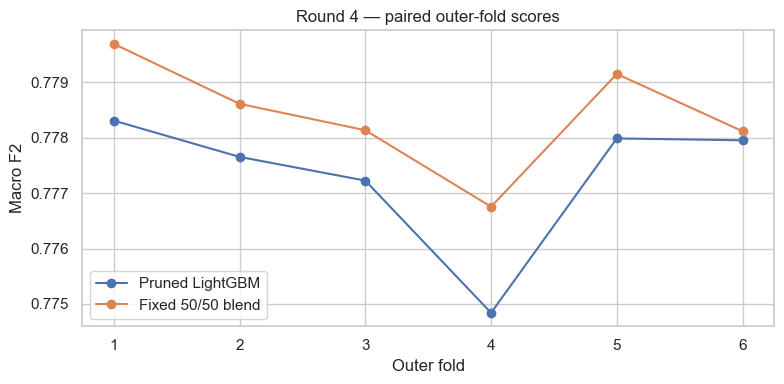

In [65]:
all_round4_pairs = pd.concat([paired_oof, paired_repeat2], ignore_index=True)
class_rows = []
for fold, group in all_round4_pairs.groupby("fold_pruned", sort=True):
    for variant, column in [("pruned", "pred_pruned"), ("50/50 blend", "blend_pred")]:
        class_rows.append({
            "fold": fold, "variant": variant,
            "F2_legitimate": fbeta_score(group.true_pruned, group[column],
                                        beta=2, pos_label=0, zero_division=0),
            "F2_cheater": fbeta_score(group.true_pruned, group[column],
                                     beta=2, pos_label=1, zero_division=0),
        })
round4_class_scores = pd.DataFrame(class_rows)
display(round4_class_scores.groupby("variant")[["F2_legitimate", "F2_cheater"]]
        .mean().round(5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(all_blend_scores.fold, all_blend_scores.pruned_macro_F2,
        marker="o", label="Pruned LightGBM")
ax.plot(all_blend_scores.fold, all_blend_scores.blend_macro_F2,
        marker="o", label="Fixed 50/50 blend")
ax.set(xlabel="Outer fold", ylabel="Macro F2",
       title="Round 4 — paired outer-fold scores")
ax.set_xticks(all_blend_scores.fold)
ax.legend()
plt.tight_layout()
plt.show()

### Round 4 decision

+- The prespecified 50/50 blend scored **0.77841** mean macro F₂ versus **0.77733** for pruned LightGBM: **+0.00108**, positive in all six paired folds. F₂ improved slightly for both classes. These repeats reuse the same 90,816 accounts, so six wins are a stability signal, not six independent confirmations.
+- The two models share **17,190 errors** on the first repeat, while each uniquely misses about two thousand accounts. There is some complementarity, but the gain is small.
+- Moving the threshold to its best value on the outer validation fold would add only **0.00012** macro F₂ on average, and that number is optimistic because it uses the outer labels. More threshold search has little evident headroom.
+- Errors concentrate in certain report, friend-network, and account-age ranges, but those are already the model's strongest inputs. The slices suggest hypotheses, not proof that a new feature will help.
+
+**Decision:** Stop broad Task 1 feature extraction and hyperparameter search for now. The blend falls below the prespecified **0.002** gain that would justify another research cycle. If time remains after other tasks, a single fixed-weight ensemble is a low-cost submission experiment; otherwise use the saved 38-feature model and move to Task 2. Test remains reserved for final predictions and format checks.